THEORETICAL BLACKJACK RESULTS
-----------------------------------
P(win) = 0.40882365780313734
P(loss) = 0.48891543790007624
P(push) = 0.10226090429678641
Sum of probabilities = 1.0

E[X_B] = -0.0800917800969389
Var(X_B) = 0.8913244024641173

MONTE CARLO BLACKJACK RESULTS
-----------------------------------
Simulated P(win) = 0.409032
Simulated P(loss) = 0.488478
Simulated P(push) = 0.10249

Simulated E[X_B] = -0.079446
Theoretical E[X_B] = -0.0800917800969389
Difference = 0.0006457800969388999
Monte Carlo standard error = 0.0013351587190024393
Difference in standard errors = 0.4836729055114833

Simulated Var(X_B) = 0.8911983330839995
Theoretical Var(X_B) = 0.8913244024641173

PASS: Simulation agrees with theoretical expected value.

BANKROLL ALLOCATION RESULTS
-----------------------------------

  Bet  Theoretical_Expected_Profit  Simulated_Mean_Profit
  0.0                    -0.000000               -0.00000
 25.0                    -2.002295               -1.98615
 50.0            

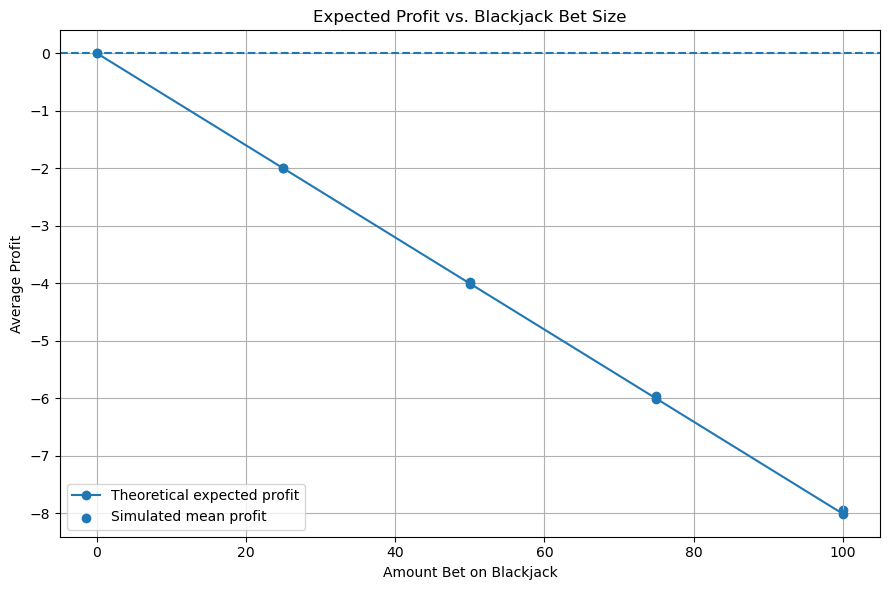

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from functools import lru_cache


# ============================================================
# PART II: BLACKJACK
# Fixed strategy:
#
# Player hits below 17 and stands on 17+
# Dealer hits below 17 and stands on 17+
#
# Payoff:
# Win  = +1
# Push =  0
# Loss = -1
# ============================================================


# Card categories:
#
# Ace = 11 initially
# 2 through 9
# 10 represents 10, J, Q, K
#
card_values = (
    11,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10
)


# Initial number of cards of each type
#
# 4 aces
# 4 each of 2 through 9
# 16 ten-valued cards
#
initial_counts = (
    4,
    4,
    4,
    4,
    4,
    4,
    4,
    4,
    4,
    16
)


# ============================================================
# Function to add one card to a hand
# ============================================================

def add_card(total, soft_aces, card):

    if card == 11:

        total += 11
        soft_aces += 1

    else:

        total += card


    # Convert an ace from 11 to 1 if necessary

    while total > 21 and soft_aces > 0:

        total -= 10
        soft_aces -= 1


    return total, soft_aces


# ============================================================
# Recursive dealer calculation
#
# Returns:
#
# probability player wins,
# probability player loses,
# probability of push
# ============================================================

@lru_cache(None)
def dealer_probabilities(
    counts,
    player_total,
    dealer_total,
    dealer_soft_aces
):

    # Dealer busts

    if dealer_total > 21:

        return (
            1.0,
            0.0,
            0.0
        )


    # Dealer stands on 17+

    if dealer_total >= 17:

        if player_total > dealer_total:

            return (
                1.0,
                0.0,
                0.0
            )

        elif player_total < dealer_total:

            return (
                0.0,
                1.0,
                0.0
            )

        else:

            return (
                0.0,
                0.0,
                1.0
            )


    cards_remaining = sum(
        counts
    )


    result = np.zeros(3)


    for i, count in enumerate(counts):

        if count == 0:
            continue


        probability = (
            count
            /
            cards_remaining
        )


        new_counts = list(
            counts
        )

        new_counts[i] -= 1


        new_total, new_soft = add_card(
            dealer_total,
            dealer_soft_aces,
            card_values[i]
        )


        next_result = dealer_probabilities(
            tuple(new_counts),
            player_total,
            new_total,
            new_soft
        )


        result += (
            probability
            *
            np.array(next_result)
        )


    return tuple(result)


# ============================================================
# Recursive player calculation
# ============================================================

@lru_cache(None)
def player_probabilities(
    counts,
    player_total,
    player_soft_aces,
    dealer_total,
    dealer_soft_aces
):

    # Player busts

    if player_total > 21:

        return (
            0.0,
            1.0,
            0.0
        )


    # Player stands on 17+

    if player_total >= 17:

        return dealer_probabilities(
            counts,
            player_total,
            dealer_total,
            dealer_soft_aces
        )


    cards_remaining = sum(
        counts
    )


    result = np.zeros(3)


    for i, count in enumerate(counts):

        if count == 0:
            continue


        probability = (
            count
            /
            cards_remaining
        )


        new_counts = list(
            counts
        )

        new_counts[i] -= 1


        new_total, new_soft = add_card(
            player_total,
            player_soft_aces,
            card_values[i]
        )


        next_result = player_probabilities(
            tuple(new_counts),
            new_total,
            new_soft,
            dealer_total,
            dealer_soft_aces
        )


        result += (
            probability
            *
            np.array(next_result)
        )


    return tuple(result)


# ============================================================
# Initial deal
#
# Deal order:
#
# Player
# Dealer
# Player
# Dealer
# ============================================================

@lru_cache(None)
def initial_deal_probabilities(
    counts,
    step,
    player_total,
    player_soft_aces,
    dealer_total,
    dealer_soft_aces
):

    if step == 4:

        return player_probabilities(
            counts,
            player_total,
            player_soft_aces,
            dealer_total,
            dealer_soft_aces
        )


    cards_remaining = sum(
        counts
    )


    result = np.zeros(3)


    for i, count in enumerate(counts):

        if count == 0:
            continue


        probability = (
            count
            /
            cards_remaining
        )


        new_counts = list(
            counts
        )

        new_counts[i] -= 1


        card = card_values[i]


        # Player receives cards 1 and 3

        if step in (0, 2):

            new_player_total, new_player_soft = add_card(
                player_total,
                player_soft_aces,
                card
            )


            next_result = initial_deal_probabilities(
                tuple(new_counts),
                step + 1,
                new_player_total,
                new_player_soft,
                dealer_total,
                dealer_soft_aces
            )


        # Dealer receives cards 2 and 4

        else:

            new_dealer_total, new_dealer_soft = add_card(
                dealer_total,
                dealer_soft_aces,
                card
            )


            next_result = initial_deal_probabilities(
                tuple(new_counts),
                step + 1,
                player_total,
                player_soft_aces,
                new_dealer_total,
                new_dealer_soft
            )


        result += (
            probability
            *
            np.array(next_result)
        )


    return tuple(result)


# ============================================================
# EXACT PROBABILITY CALCULATION
# ============================================================

p_win, p_loss, p_push = (
    initial_deal_probabilities(
        initial_counts,
        0,
        0,
        0,
        0,
        0
    )
)


expected_value = (
    p_win
    -
    p_loss
)


expected_square = (
    p_win
    +
    p_loss
)


variance = (
    expected_square
    -
    expected_value**2
)


print(
    "THEORETICAL BLACKJACK RESULTS"
)

print(
    "-----------------------------------"
)

print(
    "P(win) =",
    p_win
)

print(
    "P(loss) =",
    p_loss
)

print(
    "P(push) =",
    p_push
)

print(
    "Sum of probabilities =",
    p_win + p_loss + p_push
)

print()

print(
    "E[X_B] =",
    expected_value
)

print(
    "Var(X_B) =",
    variance
)


# ============================================================
# MONTE CARLO SIMULATION
# ============================================================

rng = np.random.default_rng(
    42
)


num_trials = 500_000


# Physical card-value deck
#
# Ace: 4
# 2-9: 4 each
# 10/J/Q/K: 16 total
#
deck_template = np.array(

    [11] * 4

    + [2] * 4
    + [3] * 4
    + [4] * 4
    + [5] * 4
    + [6] * 4
    + [7] * 4
    + [8] * 4
    + [9] * 4

    + [10] * 16,

    dtype=np.int8
)


# ============================================================
# Compute hand total
# ============================================================

def hand_total(cards):

    total = sum(
        cards
    )

    aces = sum(
        card == 11
        for card in cards
    )


    while total > 21 and aces > 0:

        total -= 10
        aces -= 1


    return total


# ============================================================
# Simulate one hand
# ============================================================

def play_one_hand(rng):

    deck = deck_template.copy()

    rng.shuffle(
        deck
    )


    # Initial deal:
    #
    # P1, D1, P2, D2

    player = [
        int(deck[0]),
        int(deck[2])
    ]

    dealer = [
        int(deck[1]),
        int(deck[3])
    ]


    next_card = 4


    # Player hits below 17

    while hand_total(player) < 17:

        player.append(
            int(deck[next_card])
        )

        next_card += 1


    player_value = hand_total(
        player
    )


    # Player bust

    if player_value > 21:

        return -1


    # Dealer hits below 17

    while hand_total(dealer) < 17:

        dealer.append(
            int(deck[next_card])
        )

        next_card += 1


    dealer_value = hand_total(
        dealer
    )


    # Dealer bust

    if dealer_value > 21:

        return 1


    # Compare hands

    if player_value > dealer_value:

        return 1


    if player_value < dealer_value:

        return -1


    return 0


# ============================================================
# Run simulation
# ============================================================

outcomes = np.fromiter(
    (
        play_one_hand(rng)
        for _ in range(num_trials)
    ),
    dtype=np.int8,
    count=num_trials
)


simulated_p_win = np.mean(
    outcomes == 1
)

simulated_p_loss = np.mean(
    outcomes == -1
)

simulated_p_push = np.mean(
    outcomes == 0
)


simulated_mean = np.mean(
    outcomes
)

simulated_variance = np.var(
    outcomes
)


# ============================================================
# Monte Carlo standard error
# ============================================================

standard_error = np.sqrt(
    variance
    /
    num_trials
)


difference = (
    simulated_mean
    -
    expected_value
)


z_score = (
    difference
    /
    standard_error
)


print()

print(
    "MONTE CARLO BLACKJACK RESULTS"
)

print(
    "-----------------------------------"
)

print(
    "Simulated P(win) =",
    simulated_p_win
)

print(
    "Simulated P(loss) =",
    simulated_p_loss
)

print(
    "Simulated P(push) =",
    simulated_p_push
)

print()

print(
    "Simulated E[X_B] =",
    simulated_mean
)

print(
    "Theoretical E[X_B] =",
    expected_value
)

print(
    "Difference =",
    difference
)

print(
    "Monte Carlo standard error =",
    standard_error
)

print(
    "Difference in standard errors =",
    z_score
)

print()

print(
    "Simulated Var(X_B) =",
    simulated_variance
)

print(
    "Theoretical Var(X_B) =",
    variance
)


if abs(z_score) < 4:

    print()

    print(
        "PASS: Simulation agrees with "
        "theoretical expected value."
    )

else:

    print()

    print(
        "WARNING: Simulation differs from "
        "theory more than expected."
    )


# ============================================================
# BANKROLL ALLOCATION
# ============================================================

B = 100.0


bet_amounts = np.array([
    0.00,
    0.25 * B,
    0.50 * B,
    0.75 * B,
    1.00 * B
])


results = []


for b_B in bet_amounts:

    theoretical_profit = (
        b_B
        *
        expected_value
    )


    simulated_profit = (
        b_B
        *
        simulated_mean
    )


    results.append({

        "Bet":
            b_B,

        "Theoretical_Expected_Profit":
            theoretical_profit,

        "Simulated_Mean_Profit":
            simulated_profit

    })


results_df = pd.DataFrame(
    results
)


print()

print(
    "BANKROLL ALLOCATION RESULTS"
)

print(
    "-----------------------------------"
)

print()

print(
    results_df.to_string(
        index=False
    )
)


# ============================================================
# Determine best strategy
# ============================================================

best_index = np.argmax(
    results_df[
        "Theoretical_Expected_Profit"
    ]
)


best_bet = results_df.loc[
    best_index,
    "Bet"
]


best_expected_profit = results_df.loc[
    best_index,
    "Theoretical_Expected_Profit"
]


print()

print(
    "OPTIMAL BLACKJACK STRATEGY"
)

print(
    "-----------------------------------"
)


print(
    "Best blackjack bet =",
    best_bet
)

print(
    "Maximum theoretical expected profit =",
    best_expected_profit
)


if best_bet == 0:

    print()

    print(
        "PASS: The expected-value maximizing "
        "strategy is to bet nothing."
    )


# ============================================================
# Plot expected profit versus bet size
# ============================================================

plt.figure(
    figsize=(9, 6)
)


plt.plot(
    results_df["Bet"],
    results_df[
        "Theoretical_Expected_Profit"
    ],
    marker="o",
    label="Theoretical expected profit"
)


plt.scatter(
    results_df["Bet"],
    results_df[
        "Simulated_Mean_Profit"
    ],
    label="Simulated mean profit"
)


plt.axhline(
    0,
    linestyle="--"
)


plt.xlabel(
    "Amount Bet on Blackjack"
)

plt.ylabel(
    "Average Profit"
)

plt.title(
    "Expected Profit vs. Blackjack Bet Size"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()


plt.savefig(
    "blackjack_bet_strategy_verification.png",
    dpi=300
)


plt.show()